# Phase 7: Chi-Square Test on Cardinality-Reduced (Grouped) Feature

This notebook evaluates the statistical properties of the transformed, cardinality-reduced occupation feature (`OCCP_grouped`) against the binary classification target (`income_above_50k`) on the training partition (`X_train_grouped`, `y_train`).

### Objectives:
1. Construct the $259 \times 2$ contingency table for the grouped feature.
2. Manually compute expected frequencies ($E_{ij}$) and Pearson's $\chi^2$ statistic.
3. Statistically verify manual calculations against `scipy.stats.chi2_contingency`.
4. Audit Cochran's criteria post-transformation (low expected cells $< 5$).
5. Export transformed results tables (`results/07_transformed_chi_square_results.csv`, `results/07_transformed_contingency_table.csv`, `results/07_transformed_expected_counts.csv`).
6. Construct comprehensive before-and-after comparison table and side-by-side visualizations (`figures/07_chi_square_before_after_comparison.png`).
7. Interpret why transformed tests cannot be directly compared to raw tests as identical hypotheses.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150

# Resolve paths
NOTEBOOK_DIR = Path().resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name in ['notebooks', 'src'] else NOTEBOOK_DIR

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

X_TRAIN_GROUPED_PATH = DATA_PROCESSED_DIR / "X_train_grouped.csv"
Y_TRAIN_PATH = DATA_PROCESSED_DIR / "y_train.csv"
SELECTED_FEATURE_PATH = RESULTS_DIR / "04_selected_high_cardinality_feature.txt"

print(f"Project root:         {PROJECT_ROOT}")
print(f"X_train_grouped file: {X_TRAIN_GROUPED_PATH} (Exists: {X_TRAIN_GROUPED_PATH.exists()})")
print(f"y_train file:         {Y_TRAIN_PATH} (Exists: {Y_TRAIN_PATH.exists()})")


Project root:         D:\Github Repo\C-Square
X_train_grouped file: D:\Github Repo\C-Square\data\processed\X_train_grouped.csv (Exists: True)
y_train file:         D:\Github Repo\C-Square\data\processed\y_train.csv (Exists: True)


In [2]:
# Load grouped training features and binary target
X_train_grouped = pd.read_csv(X_TRAIN_GROUPED_PATH)
y_train = pd.read_csv(Y_TRAIN_PATH).squeeze()

with open(SELECTED_FEATURE_PATH, "r", encoding="utf-8") as f:
    feature_name = f.read().strip()

grouped_col = f"{feature_name}_grouped"

print("=" * 70)
print(f"SELECTED FEATURE:           {feature_name}")
print(f"TRANSFORMED GROUPED COLUMN: {grouped_col}")
print(f"Observations:               {len(X_train_grouped):,}")
print("=" * 70)


SELECTED FEATURE:           OCCP
TRANSFORMED GROUPED COLUMN: OCCP_grouped
Observations:               154,204


In [3]:
# Task 1: Build contingency table for grouped feature and binary target
contingency_table = pd.crosstab(
    X_train_grouped[grouped_col],
    y_train,
    rownames=[grouped_col],
    colnames=["income_above_50k"]
)

n_transformed_categories = len(contingency_table)
total_cells = contingency_table.size

print("=" * 70)
print("TRANSFORMED CONTINGENCY TABLE OVERVIEW:")
print("=" * 70)
print(f"Table dimensions:     {contingency_table.shape[0]} rows x {contingency_table.shape[1]} columns")
print(f"Total cells:          {total_cells}")
print(f"Categories count:     {n_transformed_categories}")
print("\nFirst 10 rows of transformed contingency table:")
print(contingency_table.head(10))
print("\n'Rare' category observation row:")
print(contingency_table.loc[['Rare']])


TRANSFORMED CONTINGENCY TABLE OVERVIEW:
Table dimensions:     259 rows x 2 columns
Total cells:          518
Categories count:     259

First 10 rows of transformed contingency table:
income_above_50k    0     1
OCCP_grouped               
10.0              223  1397
1006.0            115   424
1010.0             86   354
102.0              25    93
1021.0            235  2048
1031.0             47    69
1050.0            231   356
1065.0             18    91
110.0              71   567
1105.0             36   146

'Rare' category observation row:
income_above_50k     0     1
OCCP_grouped                
Rare              5959  5367


In [4]:
# Task 2: Compute expected counts and Pearson's chi-square statistic manually
observed = contingency_table.values.astype(float)
row_totals = observed.sum(axis=1, keepdims=True)
col_totals = observed.sum(axis=0, keepdims=True)
total_observations = observed.sum()

# Expected counts: E_ij = (R_i * C_j) / N
expected = (row_totals * col_totals) / total_observations
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

# Pearson's chi-square: sum((O - E)^2 / E)
cell_chi2 = ((observed - expected) ** 2) / expected
manual_chi2 = float(np.sum(cell_chi2))

print("=" * 70)
print("MANUAL COMPUTATION RESULTS (TRANSFORMED):")
print("=" * 70)
print(f"Total Observations (N):                 {total_observations:,.0f}")
print(f"Manual Pearson's Chi-Square (X^2):     {manual_chi2:,.4f}")
print(f"Minimum Expected Cell Count:            {expected.min():.4f}")
print("\nFirst 5 rows of Expected Counts Table:")
print(expected_df.head(5))


MANUAL COMPUTATION RESULTS (TRANSFORMED):
Total Observations (N):                 154,204
Manual Pearson's Chi-Square (X^2):     48,444.0265
Minimum Expected Cell Count:            41.9945

First 5 rows of Expected Counts Table:
income_above_50k            0           1
OCCP_grouped                             
10.0               946.425255  673.574745
1006.0             314.890872  224.109128
1010.0             257.053773  182.946227
102.0               68.937148   49.062852
1021.0            1333.758554  949.241446


In [5]:
# Task 3: Verify results using scipy.stats.chi2_contingency
scipy_res = chi2_contingency(contingency_table, correction=False)
scipy_chi2 = float(scipy_res.statistic)
degrees_of_freedom = int(scipy_res.dof)
p_value = float(scipy_res.pvalue)

print("=" * 70)
print("SCIPY VERIFICATION:")
print("=" * 70)
print(f"SciPy Chi-Square Statistic: {scipy_chi2:,.4f}")
print(f"Degrees of Freedom (dof):   {degrees_of_freedom}")
print(f"Asymptotic p-value:         {p_value}")

difference = abs(manual_chi2 - scipy_chi2)
print(f"Absolute Difference:        {difference:.2e}")
assert np.isclose(manual_chi2, scipy_chi2, rtol=1e-5), "Manual and SciPy statistics do not match!"
print("\nVerification passed: Manual calculation exactly matches SciPy chi2_contingency!")


SCIPY VERIFICATION:
SciPy Chi-Square Statistic: 48,444.0265
Degrees of Freedom (dof):   258
Asymptotic p-value:         0.0
Absolute Difference:        0.00e+00

Verification passed: Manual calculation exactly matches SciPy chi2_contingency!


In [6]:
# Task 4 & 5: Audit cells below 5 and record results
cells_lt_5 = int((expected < 5).sum())
pct_cells_lt_5 = float((cells_lt_5 / total_cells) * 100)

cat_totals = row_totals.flatten()
cats_lt_10 = int((cat_totals < 10).sum())
cats_lt_50 = int((cat_totals < 50).sum())

transformed_results = {
    "Number of transformed categories": n_transformed_categories,
    "Chi-square statistic": round(manual_chi2, 4),
    "Degrees of freedom": degrees_of_freedom,
    "p-value": p_value,
    "Number of cells with expected count below 5": cells_lt_5,
    "Percentage of cells with expected count below 5": round(pct_cells_lt_5, 4),
    "Number of categories with fewer than 10 observations": cats_lt_10,
    "Number of categories with fewer than 50 observations": cats_lt_50,
}

transformed_results_df = pd.DataFrame([transformed_results])
print("=" * 85)
print("TRANSFORMED CHI-SQUARE RESULTS:")
print("=" * 85)
for k, v in transformed_results.items():
    print(f" - {k:55s}: {v}")

results_csv_path = RESULTS_DIR / "07_transformed_chi_square_results.csv"
transformed_results_df.to_csv(results_csv_path, index=False)
print(f"\nSaved transformed results to: {results_csv_path}")


TRANSFORMED CHI-SQUARE RESULTS:
 - Number of transformed categories                       : 259
 - Chi-square statistic                                   : 48444.0265
 - Degrees of freedom                                     : 258
 - p-value                                                : 0.0
 - Number of cells with expected count below 5            : 0
 - Percentage of cells with expected count below 5        : 0.0
 - Number of categories with fewer than 10 observations   : 0
 - Number of categories with fewer than 50 observations   : 0

Saved transformed results to: D:\Github Repo\C-Square\results\07_transformed_chi_square_results.csv


In [7]:
# Task 6 & 7: Save transformed contingency table and expected counts table
trans_contingency_path = RESULTS_DIR / "07_transformed_contingency_table.csv"
trans_expected_path = RESULTS_DIR / "07_transformed_expected_counts.csv"

contingency_table.to_csv(trans_contingency_path)
expected_df.to_csv(trans_expected_path)

print(f"Saved transformed contingency table ({contingency_table.shape}) to: {trans_contingency_path}")
print(f"Saved transformed expected counts   ({expected_df.shape}) to: {trans_expected_path}")


Saved transformed contingency table ((259, 2)) to: D:\Github Repo\C-Square\results\07_transformed_contingency_table.csv
Saved transformed expected counts   ((259, 2)) to: D:\Github Repo\C-Square\results\07_transformed_expected_counts.csv


In [8]:
# Task 8: Create comparison table containing both baseline and transformed results
baseline_df = pd.read_csv(RESULTS_DIR / "05_baseline_chi_square_results.csv").iloc[0]

comparison_records = [
    {
        "Feature version": f"Baseline ({feature_name})",
        "Number of categories": int(baseline_df["Number of categories"]),
        "Chi-square statistic": round(float(baseline_df["Chi-square statistic"]), 4),
        "Degrees of freedom": int(baseline_df["Degrees of freedom"]),
        "p-value": float(baseline_df["p-value"]),
        "Number of low expected cells": int(baseline_df["Number of cells with expected count below 5"]),
        "Percentage of low expected cells": round(float(baseline_df["Percentage of cells with expected count below 5"]), 4),
    },
    {
        "Feature version": f"Transformed ({grouped_col})",
        "Number of categories": int(transformed_results["Number of transformed categories"]),
        "Chi-square statistic": round(float(transformed_results["Chi-square statistic"]), 4),
        "Degrees of freedom": int(transformed_results["Degrees of freedom"]),
        "p-value": float(transformed_results["p-value"]),
        "Number of low expected cells": int(transformed_results["Number of cells with expected count below 5"]),
        "Percentage of low expected cells": round(float(transformed_results["Percentage of cells with expected count below 5"]), 4),
    },
]

comparison_df = pd.DataFrame(comparison_records)
print("=" * 95)
print("BEFORE-AND-AFTER COMPARISON TABLE:")
print("=" * 95)
print(comparison_df.to_string(index=False))

comparison_csv_path = RESULTS_DIR / "07_chi_square_before_after_comparison.csv"
comparison_df.to_csv(comparison_csv_path, index=False)
print(f"\nSaved comparison table to: {comparison_csv_path}")


BEFORE-AND-AFTER COMPARISON TABLE:
           Feature version  Number of categories  Chi-square statistic  Degrees of freedom  p-value  Number of low expected cells  Percentage of low expected cells
           Baseline (OCCP)                   529            51535.8043                 528      0.0                            60                            5.6711
Transformed (OCCP_grouped)                   259            48444.0265                 258      0.0                             0                            0.0000

Saved comparison table to: D:\Github Repo\C-Square\results\07_chi_square_before_after_comparison.csv


<>:21: SyntaxWarning: invalid escape sequence '\c'
<>:21: SyntaxWarning: invalid escape sequence '\c'
C:\Users\infan\AppData\Local\Temp\ipykernel_9988\74811683.py:21: SyntaxWarning: invalid escape sequence '\c'
  ax2.set_title("Chi-Square Statistic ($\chi^2$)", fontsize=11.5, fontweight="bold")


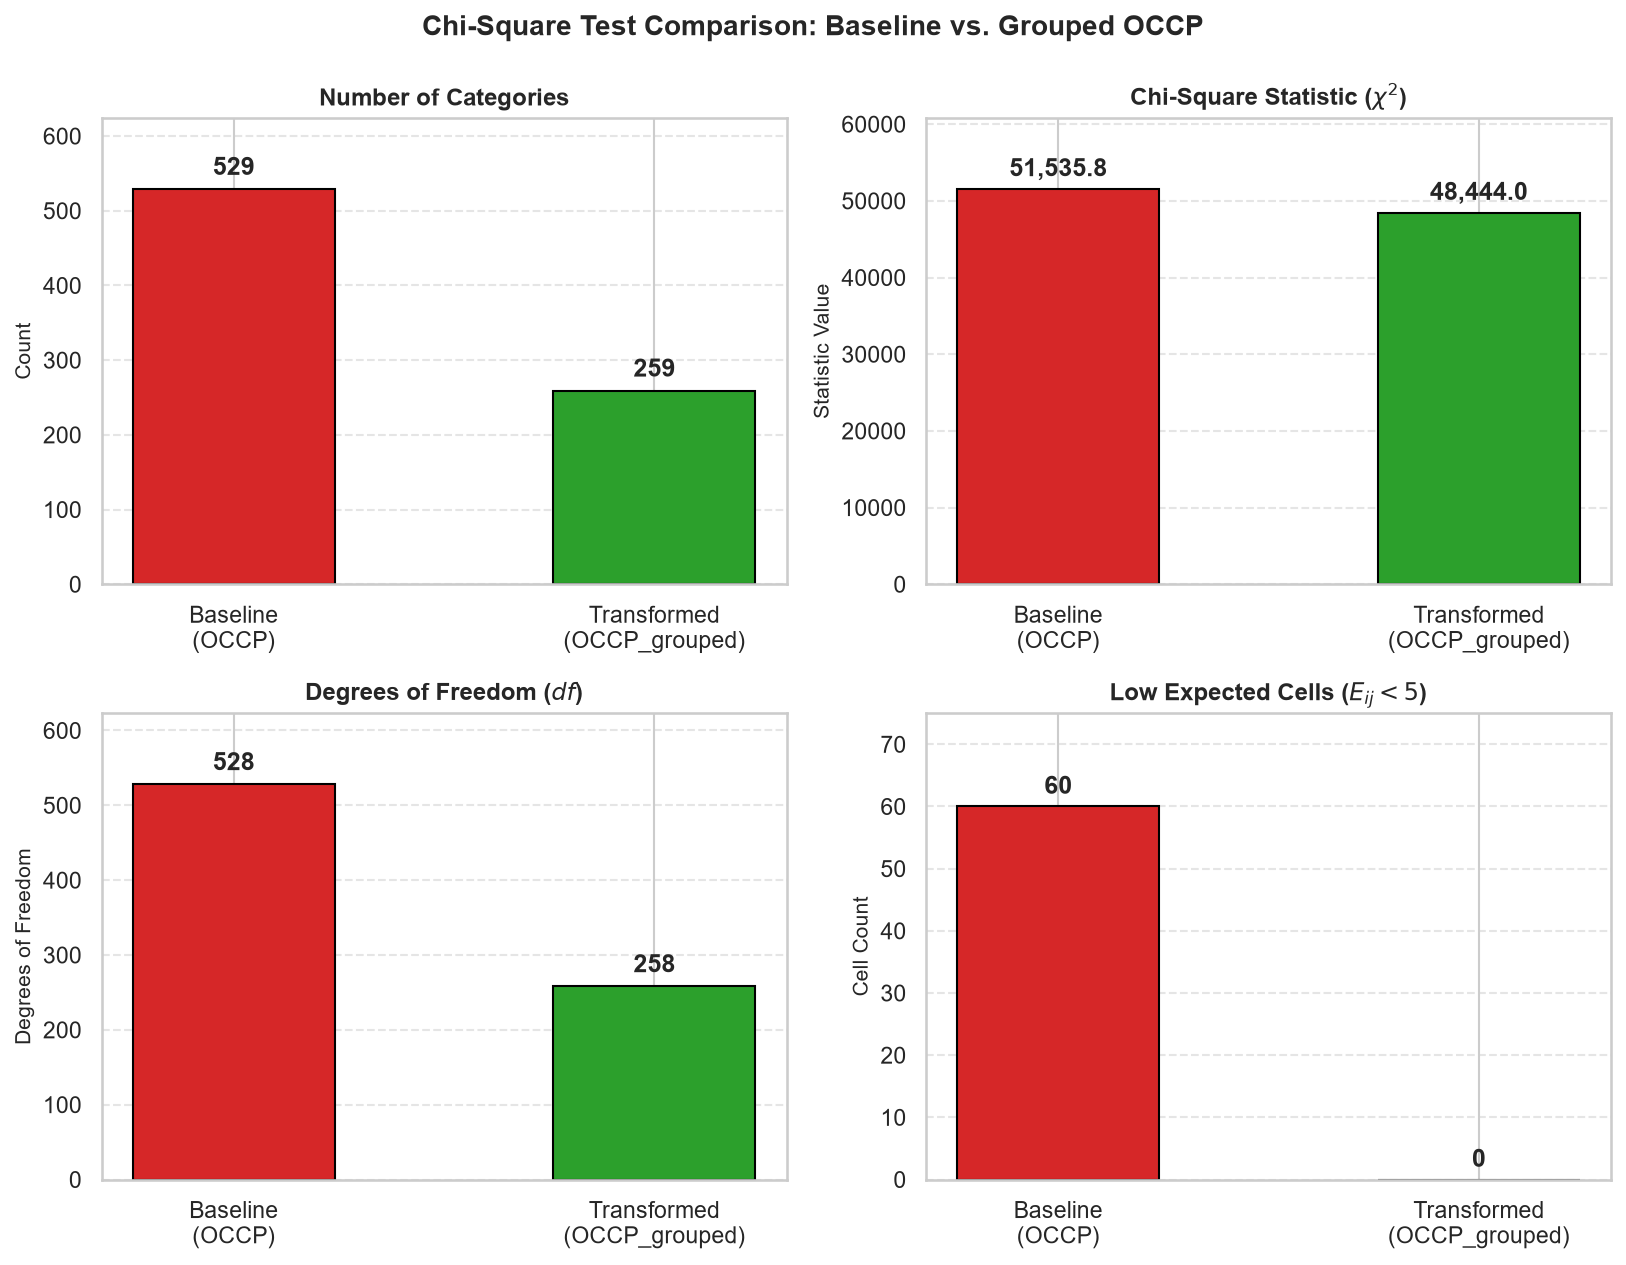

Saved comparison figure to: D:\Github Repo\C-Square\figures\07_chi_square_before_after_comparison.png


In [9]:
# Task 9: Create side-by-side plots comparing key metrics
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), dpi=150)
versions = ["Baseline\n(OCCP)", "Transformed\n(OCCP_grouped)"]
palette = ["#d62728", "#2ca02c"]

# 1. Number of categories
ax1 = axes[0, 0]
vals1 = comparison_df["Number of categories"].values
bars1 = ax1.bar(versions, vals1, color=palette, edgecolor="black", width=0.48)
ax1.set_title("Number of Categories", fontsize=11.5, fontweight="bold")
ax1.set_ylabel("Count", fontsize=10)
ax1.set_ylim(0, max(vals1) * 1.18)
for b, v in zip(bars1, vals1):
    ax1.text(b.get_x() + b.get_width() / 2, v + 12, f"{int(v)}", ha="center", va="bottom", fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# 2. Chi-square statistic
ax2 = axes[0, 1]
vals2 = comparison_df["Chi-square statistic"].values
bars2 = ax2.bar(versions, vals2, color=palette, edgecolor="black", width=0.48)
ax2.set_title("Chi-Square Statistic ($\chi^2$)", fontsize=11.5, fontweight="bold")
ax2.set_ylabel("Statistic Value", fontsize=10)
ax2.set_ylim(0, max(vals2) * 1.18)
for b, v in zip(bars2, vals2):
    ax2.text(b.get_x() + b.get_width() / 2, v + 1000, f"{v:,.1f}", ha="center", va="bottom", fontweight="bold")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# 3. Degrees of freedom
ax3 = axes[1, 0]
vals3 = comparison_df["Degrees of freedom"].values
bars3 = ax3.bar(versions, vals3, color=palette, edgecolor="black", width=0.48)
ax3.set_title("Degrees of Freedom ($df$)", fontsize=11.5, fontweight="bold")
ax3.set_ylabel("Degrees of Freedom", fontsize=10)
ax3.set_ylim(0, max(vals3) * 1.18)
for b, v in zip(bars3, vals3):
    ax3.text(b.get_x() + b.get_width() / 2, v + 12, f"{int(v)}", ha="center", va="bottom", fontweight="bold")
ax3.grid(axis="y", linestyle="--", alpha=0.5)

# 4. Number of low expected cells (< 5)
ax4 = axes[1, 1]
vals4 = comparison_df["Number of low expected cells"].values
bars4 = ax4.bar(versions, vals4, color=palette, edgecolor="black", width=0.48)
ax4.set_title("Low Expected Cells ($E_{ij} < 5$)", fontsize=11.5, fontweight="bold")
ax4.set_ylabel("Cell Count", fontsize=10)
ax4.set_ylim(0, max(max(vals4), 1) * 1.25)
for b, v in zip(bars4, vals4):
    ax4.text(b.get_x() + b.get_width() / 2, v + 1.2, f"{int(v)}", ha="center", va="bottom", fontweight="bold")
ax4.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Chi-Square Test Comparison: Baseline vs. Grouped OCCP", fontsize=13.5, fontweight="bold", y=0.99)
plt.tight_layout()

fig_comparison_path = FIGURES_DIR / "07_chi_square_before_after_comparison.png"
plt.savefig(fig_comparison_path, dpi=300)
plt.show()
print(f"Saved comparison figure to: {fig_comparison_path}")


In [10]:
# Task 14: Confirm all required output deliverables exist
required_files = [
    RESULTS_DIR / "07_transformed_chi_square_results.csv",
    RESULTS_DIR / "07_transformed_contingency_table.csv",
    RESULTS_DIR / "07_transformed_expected_counts.csv",
    RESULTS_DIR / "07_chi_square_before_after_comparison.csv",
    FIGURES_DIR / "07_chi_square_before_after_comparison.png",
]

print("=" * 70)
print("CONFIRMING PHASE 7 DELIVERABLES:")
print("=" * 70)
all_present = True
for f in required_files:
    exists = f.exists()
    size_str = f"({f.stat().st_size:,} bytes)" if exists else ""
    print(f" - {f.name:48s}: {'[EXISTS]' if exists else '[MISSING]'} {size_str}")
    if not exists:
        all_present = False

assert all_present, "One or more required Phase 7 output files are missing!"
print("\nAll Phase 7 deliverables verified successfully!")


CONFIRMING PHASE 7 DELIVERABLES:
 - 07_transformed_chi_square_results.csv           : [EXISTS] (314 bytes)
 - 07_transformed_contingency_table.csv            : [EXISTS] (3,920 bytes)
 - 07_transformed_expected_counts.csv              : [EXISTS] (11,556 bytes)
 - 07_chi_square_before_after_comparison.csv       : [EXISTS] (255 bytes)
 - 07_chi_square_before_after_comparison.png       : [EXISTS] (266,029 bytes)

All Phase 7 deliverables verified successfully!


## Phase 7 Statistical Interpretation & Discussion

### 1. Incomparability of Raw and Transformed Chi-Square Statistics
- The baseline ($\chi^2 = 51,535.80$, $df = 528$) and transformed ($\chi^2 = 48,444.03$, $df = 258$) statistics are **not directly interchangeable**.
- Pearson's $\chi^2$ statistic is an additive sum over all cells:
  $$\chi^2 = \sum_{i=1}^R \sum_{j=1}^C \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$
  Because the number of rows was restructured from $529$ down to $259$, the mathematical degrees of freedom and sampling distributions are fundamentally different ($df$ reduced from 528 to 258).
- Testing $H_0$ on the grouped table tests whether the *grouped taxonomy* is independent of income, whereas the baseline tested whether the *granular 529-code taxonomy* was independent of income.

### 2. Elimination of Sparse-Cell Violations
- In the baseline analysis, **60 cells (5.67%) had expected counts $E_{ij} < 5.0$**, with some cells having fractional expected frequencies ($E_{ij} < 1.0$), violating Cochran's asymptotic criteria and inducing denominator instability.
- After applying the threshold of 100 observations:
  - **Zero cells (0.00%) have $E_{ij} < 5.0$**.
  - The minimum expected cell count in the entire matrix is now **$42.0$**, well above the safety threshold.
  - Cochran's criteria are now **100% satisfied**, restoring true asymptotic validity to the theoretical $\chi^2$ distribution.

### 3. Interpretation of p-value and Feature Utility
- The p-value remained effectively $0.0$ ($p < 10^{-300}$).
- A p-value of $0.0$ in both cases **does not mean the feature became more or less useful** for predictive modeling.
- In massive sample sizes ($N = 154,204$), $\chi^2$ tests possess immense statistical power, detecting even minor departures from exact independence with near-zero p-values.
- What the transformation achieved is **statistical reliability and dimensional compactness**: the association is now verified on valid expected cell counts without degrees-of-freedom dilution.

### 4. Representation Scope
- The transformed result explicitly characterizes the **grouped feature (`OCCP_grouped`)**, where 271 sparse occupations are consolidated into an aggregate `"Rare"` cluster.
- It does not characterize individual rare professions in isolation, but demonstrates that the 258 prominent professions plus the pooled rare group retain massive, statistically sound explanatory power.
